# Week 6 – Feature Engineering, Scaling, Encoding and Skewness
## Ames Housing Dataset | 24ADI204 – Data Science & Visualization

**Syllabus mapping:** Unit 3  
**Input:** `../Week 5/Cleaned_AmesHousing_Week5.csv`  
**Primary output:** `Feature_Engineered_AmesHousing.csv`

### Learning objectives
1. Inspect the cleaned Week 5 dataset and identify numerical, nominal and ordinal features.
2. Create meaningful housing features using domain knowledge.
3. Measure skewness and apply `log1p` only to suitable non-negative, positively skewed variables.
4. Compare Min-Max, Standard and Robust scaling using actual transformed values.
5. Encode ordinal categories according to their order and one-hot encode nominal categories.
6. Export a reproducible feature-engineered dataset and supporting evidence.

> **Pipeline rule:** This notebook starts from the Week 5 cleaned dataset. It does not overwrite Week 5 files. The main feature-engineered export remains unscaled so Week 7 can apply its own StandardScaler before PCA. Separate scaling exports are created to demonstrate each scaling method without mixing multiple scaled copies into the PCA input.

## 1. Import libraries and set project paths

Run this notebook from the repository root or open it in Jupyter. The path resolver checks the expected Week 5 location first and then a local fallback. All new outputs are saved under `Week 6/week6_outputs/`.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "Week 6":
    REPO_ROOT = NOTEBOOK_DIR.parent
else:
    REPO_ROOT = NOTEBOOK_DIR

input_candidates = [
    REPO_ROOT / "Week 5" / "Cleaned_AmesHousing_Week5.csv",
    REPO_ROOT / "Cleaned_AmesHousing_Week5.csv",
]
input_path = next((p for p in input_candidates if p.exists()), None)
if input_path is None:
    raise FileNotFoundError(
        "Week 5 cleaned dataset was not found. Expected "
        "'Week 5/Cleaned_AmesHousing_Week5.csv'. Run Week 5 first."
    )

OUTPUT_DIR = REPO_ROOT / "Week 6" / "week6_outputs"
FIGURE_DIR = OUTPUT_DIR / "Figures"
SCALED_DIR = OUTPUT_DIR / "scaled_datasets"
for folder in (OUTPUT_DIR, FIGURE_DIR, SCALED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Input file: {input_path.relative_to(REPO_ROOT)}")
print(f"Output folder: {OUTPUT_DIR.relative_to(REPO_ROOT)}")

Input file: Week 5/Cleaned_AmesHousing_Week5.csv
Output folder: Week 6/week6_outputs


## 2. Load and audit the Week 5 cleaned dataset

A cleaned dataset should be checked again before feature engineering. We verify dimensions, duplicate rows, missing cells and column types. The `MS SubClass` field is a building-class code, so it is treated as a nominal category rather than as a continuous measurement.

For numerical missing values that remain, this notebook uses the column median. For categorical missing values it uses the explicit label `Unknown`. These are safeguards; the expected Week 5 deliverable should already contain no missing values.

In [2]:
raw_df = pd.read_csv(input_path, low_memory=False, keep_default_na=False)
# Preserve the meaningful text label "None" for structural absences, while treating blank cells as missing.
raw_df = raw_df.replace(r"^\s*$", pd.NA, regex=True)
df = raw_df.copy()

ID_COLS = [c for c in ["Order", "PID"] if c in df.columns]
TARGET_COLS = [c for c in ["SalePrice", "SalePrice_Log"] if c in df.columns]
if "SalePrice" not in df.columns:
    raise KeyError("Required target column 'SalePrice' is missing from the Week 5 dataset.")

# Convert known numerical fields safely, even if a CSV reader inferred an object dtype.
known_numeric = [
    "Order", "PID", "MS SubClass", "Lot Frontage", "Lot Area", "Overall Qual",
    "Overall Cond", "Year Built", "Year Remod/Add", "Mas Vnr Area", "BsmtFin SF 1",
    "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF",
    "Low Qual Fin SF", "Gr Liv Area", "Bsmt Full Bath", "Bsmt Half Bath", "Full Bath",
    "Half Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd", "Fireplaces",
    "Garage Yr Blt", "Garage Cars", "Garage Area", "Wood Deck SF", "Open Porch SF",
    "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Pool Area", "Misc Val",
    "Mo Sold", "Yr Sold", "SalePrice", "SalePrice_Log"
]
for col in known_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# MS SubClass is a nominal building-type code, not a continuous measurement.
if "MS SubClass" in df.columns:
    subclass = pd.to_numeric(df["MS SubClass"], errors="coerce")
    df["MS SubClass"] = subclass.astype("Int64").astype("string")

# Capture data quality before safe imputation.
missing_before = int(df.isna().sum().sum())
duplicates_before = int(df.duplicated().sum())

ordinal_maps = {
    "Exter Qual": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Exter Cond": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Bsmt Qual": {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Bsmt Cond": {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Heating QC": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Kitchen Qual": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Fireplace Qu": {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Garage Qual": {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Garage Cond": {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "Pool QC": {"None": 0, "Fa": 1, "TA": 2, "Gd": 3, "Ex": 4},
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Central Air": {"N": 0, "Y": 1},
}

ordinal_present = [c for c in ordinal_maps if c in df.columns]
for col in ordinal_present:
    # Blank strings are treated as unrecorded, not as the meaningful 'None' category.
    df[col] = df[col].astype("string").str.strip().replace({"": pd.NA})

# Impute genuine missing values after retaining a before-imputation count.
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            median = df[col].median()
            df[col] = df[col].fillna(median if pd.notna(median) else 0)
        else:
            df[col] = df[col].fillna("Unknown")

# Validate the ordinal categories before mapping. Never silently turn an unknown value into zero.
ordinal_validation = []
for col in ordinal_present:
    allowed = set(ordinal_maps[col])
    observed = set(df[col].dropna().astype(str).unique())
    unknown = sorted(observed - allowed)
    ordinal_validation.append({"Feature": col, "Observed categories": len(observed), "Unknown categories": ", ".join(unknown) if unknown else "None"})
    if unknown:
        raise ValueError(f"Unrecognized category in ordinal feature '{col}': {unknown}. Review source values and update the mapping explicitly.")

# Create a concise quality audit.
quality_audit = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells before safeguard imputation", "Missing cells after safeguard imputation", "Duplicate rows before processing", "Ordinal columns validated"],
    "Value": [len(df), df.shape[1], missing_before, int(df.isna().sum().sum()), duplicates_before, len(ordinal_present)]
})
display(quality_audit)
display(pd.DataFrame(ordinal_validation))
quality_audit.to_csv(OUTPUT_DIR / "week6_input_data_audit.csv", index=False)
print("Week 5 input loaded and checked.")

,Metric,Value
0,Rows,2930
1,Columns,82
2,Missing cells before safeguard imputation,0
3,Missing cells after safeguard imputation,0
4,Duplicate rows before processing,0
5,Ordinal columns validated,21


,Feature,Observed categories,Unknown categories
0,Exter Qual,4,None
1,Exter Cond,5,None
2,Bsmt Qual,6,None
3,Bsmt Cond,6,None
4,Heating QC,5,None
5,Kitchen Qual,5,None
6,Fireplace Qu,6,None
7,Garage Qual,6,None
8,Garage Cond,6,None
9,Pool QC,5,None


Week 5 input loaded and checked.


## 3. Identify numerical, nominal and ordinal features

Ordinal features have a meaningful order and are encoded using documented rankings. Nominal features have no inherent order and are one-hot encoded. `MS SubClass` is included with nominal categories because its numbers are class labels.

The exact counts are calculated from the dataset rather than hardcoded. This prevents the markdown and notebook output from reporting contradictory feature counts.

In [3]:
ordinal_present = [c for c in ordinal_maps if c in df.columns]
nominal_cols = [
    c for c in df.select_dtypes(include=["object", "string", "category"]).columns
    if c not in ordinal_present
]
numeric_cols_initial = [c for c in df.select_dtypes(include=np.number).columns if c not in ID_COLS]

feature_type_summary = pd.DataFrame({
    "Feature type": ["Numerical", "Ordinal categorical", "Nominal categorical"],
    "Count": [len(numeric_cols_initial), len(ordinal_present), len(nominal_cols)]
})
display(feature_type_summary)

encoding_summary = pd.DataFrame([
    {"Feature": c, "Encoding": "Ordinal", "Categories": " → ".join(ordinal_maps[c].keys())}
    for c in ordinal_present
] + [
    {"Feature": c, "Encoding": "One-Hot", "Categories": int(df[c].nunique(dropna=False))}
    for c in nominal_cols
])
display(encoding_summary.head(30))
encoding_summary.to_csv(OUTPUT_DIR / "week6_feature_type_and_encoding_summary.csv", index=False)

,Feature type,Count
0,Numerical,36
1,Ordinal categorical,21
2,Nominal categorical,23


,Feature,Encoding,Categories
0,Exter Qual,Ordinal,Po → Fa → TA → Gd → Ex
1,Exter Cond,Ordinal,Po → Fa → TA → Gd → Ex
2,Bsmt Qual,Ordinal,None → Po → Fa → TA → Gd → Ex
3,Bsmt Cond,Ordinal,None → Po → Fa → TA → Gd → Ex
4,Heating QC,Ordinal,Po → Fa → TA → Gd → Ex
5,Kitchen Qual,Ordinal,Po → Fa → TA → Gd → Ex
6,Fireplace Qu,Ordinal,None → Po → Fa → TA → Gd → Ex
7,Garage Qual,Ordinal,None → Po → Fa → TA → Gd → Ex
8,Garage Cond,Ordinal,None → Po → Fa → TA → Gd → Ex
9,Pool QC,Ordinal,None → Fa → TA → Gd → Ex


## 4. Domain-based feature engineering

The following derived features summarize housing characteristics:

- `HouseAge = Yr Sold − Year Built`
- `RemodAge = Yr Sold − Year Remod/Add`
- `TotalBathrooms = Full Bath + 0.5 × Half Bath + Bsmt Full Bath + 0.5 × Bsmt Half Bath`
- `TotalPorchArea = Open Porch SF + Enclosed Porch + 3Ssn Porch + Screen Porch + Wood Deck SF`
- `TotalHouseArea = Gr Liv Area + Total Bsmt SF`

A feature is created only when all of its source columns are present. The code reports which features were successfully created.

In [4]:
feature_definitions = {
    "HouseAge": (["Yr Sold", "Year Built"], lambda d: d["Yr Sold"] - d["Year Built"]),
    "RemodAge": (["Yr Sold", "Year Remod/Add"], lambda d: d["Yr Sold"] - d["Year Remod/Add"]),
    "TotalBathrooms": (["Full Bath", "Half Bath", "Bsmt Full Bath", "Bsmt Half Bath"], lambda d: d["Full Bath"] + 0.5*d["Half Bath"] + d["Bsmt Full Bath"] + 0.5*d["Bsmt Half Bath"]),
    "TotalPorchArea": (["Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Wood Deck SF"], lambda d: d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"] + d["Wood Deck SF"]),
    "TotalHouseArea": (["Gr Liv Area", "Total Bsmt SF"], lambda d: d["Gr Liv Area"] + d["Total Bsmt SF"]),
}
created_features, skipped_features = [], []
for name, (sources, formula) in feature_definitions.items():
    if all(c in df.columns for c in sources):
        df[name] = formula(df)
        created_features.append(name)
    else:
        skipped_features.append({"Feature": name, "Missing source columns": ", ".join(c for c in sources if c not in df.columns)})

print("Created features:", created_features)
if skipped_features:
    print("Not created because source columns are unavailable:")
    display(pd.DataFrame(skipped_features))
else:
    print("All five planned domain features were created.")
display(df[[c for c in created_features]].describe().T if created_features else pd.DataFrame())

Created features: ['HouseAge', 'RemodAge', 'TotalBathrooms', 'TotalPorchArea', 'TotalHouseArea']
All five planned domain features were created.


,count,mean,std,min,25%,50%,75%,max
HouseAge,2930.0,36.434130,30.291357,-1.0,7.0,34.0,54.00,136.0
RemodAge,2930.0,23.523891,20.858846,-2.0,4.0,15.0,42.75,60.0
TotalBathrooms,2930.0,2.217918,0.807444,1.0,1.5,2.0,2.50,7.0
TotalPorchArea,2930.0,182.891468,159.834420,0.0,48.0,165.0,266.00,1424.0
TotalHouseArea,2930.0,2550.946075,805.253248,334.0,2004.0,2452.0,2994.50,11752.0


## 5. Skewness analysis and `log1p` transformation

Skewness is calculated from the current dataset. A right-skewed non-negative variable with skewness greater than 1 is considered for a `log1p` transformation. This is a screening rule, not an instruction to transform every column.

`log1p(x) = log(1 + x)` is defined for zero and positive values. The original columns are preserved, and transformed columns are added with a `_Log1p` suffix. `SalePrice_Log` is retained as the target transformation used by later project stages.

,Feature,Skewness before,Non-negative,Transformed,Output column,Skewness after
19,Misc Val,21.9998,True,True,Misc Val_Log1p,5.2275
18,Pool Area,16.9391,True,True,Pool Area_Log1p,15.0346
2,Lot Area,12.8209,True,True,Lot Area_Log1p,-0.4983
10,Low Qual Fin SF,12.1182,True,True,Low Qual Fin SF_Log1p,8.5788
16,3Ssn Porch,11.4038,True,True,3Ssn Porch_Log1p,8.8470
5,BsmtFin SF 2,4.1408,True,True,BsmtFin SF 2_Log1p,2.4503
15,Enclosed Porch,4.0144,True,True,Enclosed Porch_Log1p,1.9683
17,Screen Porch,3.9575,True,True,Screen Porch_Log1p,2.9548
3,Mas Vnr Area,2.6193,True,True,Mas Vnr Area_Log1p,0.5420
14,Open Porch SF,2.5354,True,True,Open Porch SF_Log1p,-0.0463


SalePrice skewness before: 1.7435
SalePrice skewness after log1p: -0.0148
Transformed columns: ['SalePrice_Log', 'Lot Frontage_Log1p', 'Lot Area_Log1p', 'Mas Vnr Area_Log1p', 'BsmtFin SF 1_Log1p', 'BsmtFin SF 2_Log1p', 'Total Bsmt SF_Log1p', '1st Flr SF_Log1p', 'Low Qual Fin SF_Log1p', 'Gr Liv Area_Log1p', 'Wood Deck SF_Log1p', 'Open Porch SF_Log1p', 'Enclosed Porch_Log1p', '3Ssn Porch_Log1p', 'Screen Porch_Log1p', 'Pool Area_Log1p', 'Misc Val_Log1p', 'TotalPorchArea_Log1p', 'TotalHouseArea_Log1p']


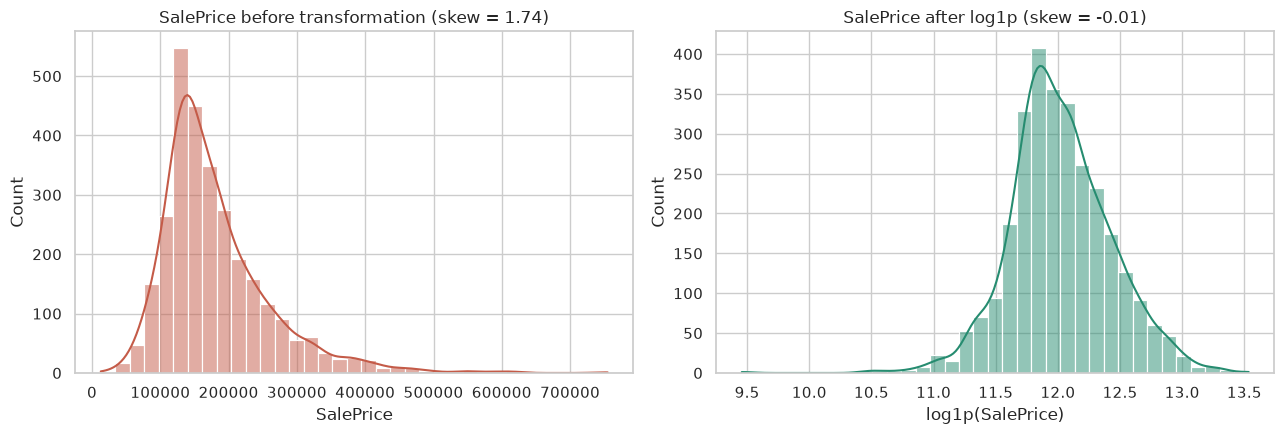

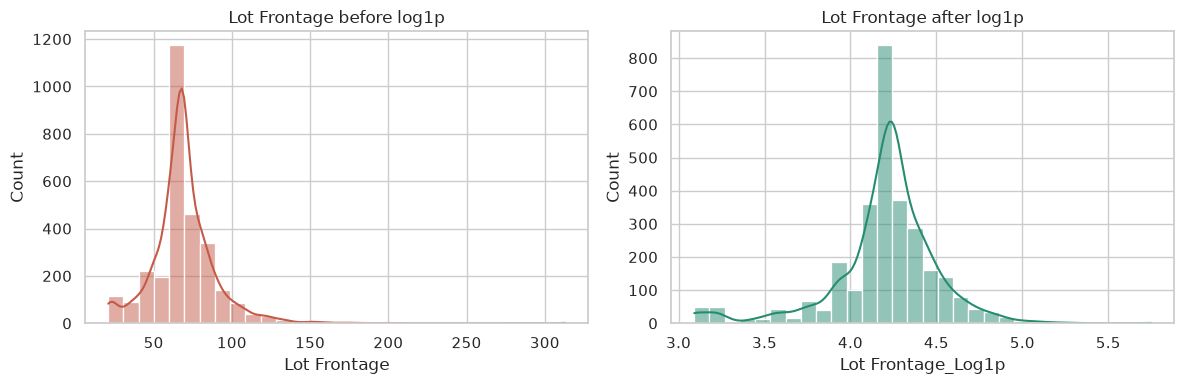

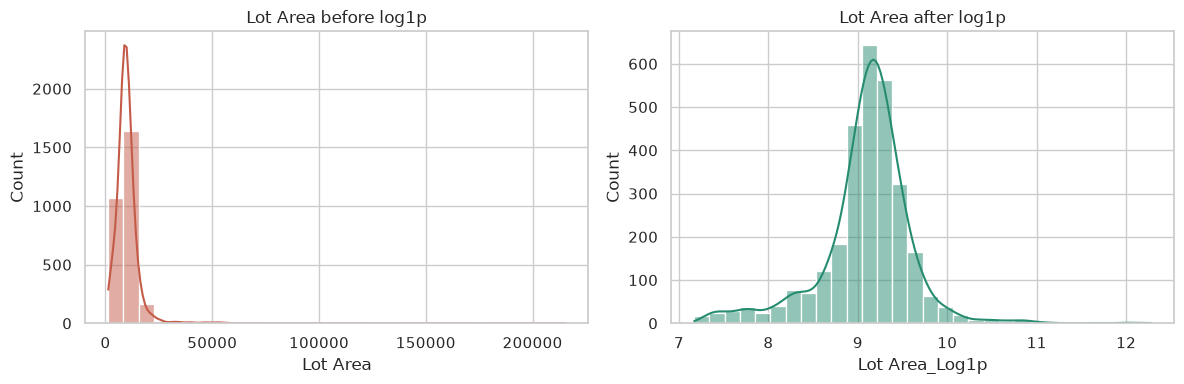

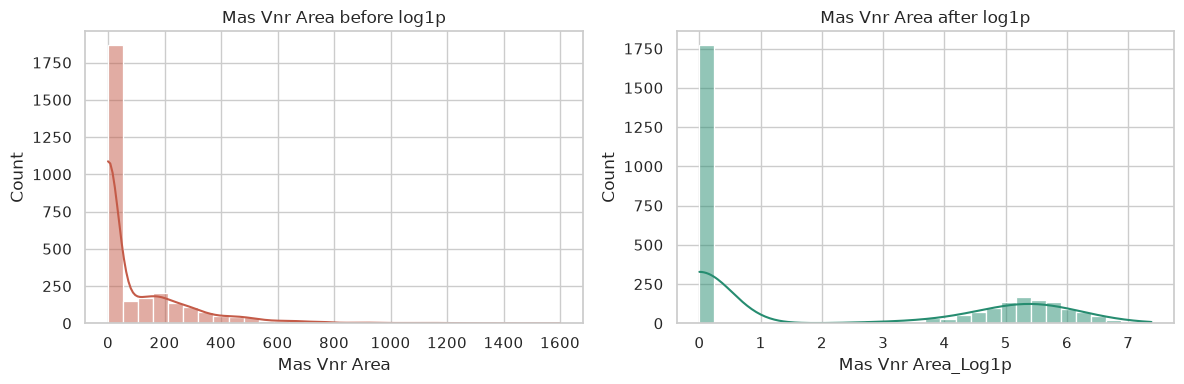

In [5]:
# Numeric measurement candidates; IDs and category codes are deliberately excluded.
measurement_candidates = [
    "SalePrice", "Lot Frontage", "Lot Area", "Mas Vnr Area", "BsmtFin SF 1",
    "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF",
    "Low Qual Fin SF", "Gr Liv Area", "Garage Area", "Wood Deck SF", "Open Porch SF",
    "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Pool Area", "Misc Val",
    "TotalPorchArea", "TotalHouseArea"
]
measurement_candidates = [c for c in measurement_candidates if c in df.columns]

skew_rows = []
transformed_columns = []
for col in measurement_candidates:
    values = pd.to_numeric(df[col], errors="coerce")
    before_skew = float(values.skew()) if values.notna().sum() > 2 else np.nan
    is_nonnegative = bool((values.dropna() >= 0).all())
    should_transform = pd.notna(before_skew) and before_skew > 1.0 and is_nonnegative
    output_col = None
    after_skew = np.nan
    if should_transform:
        output_col = "SalePrice_Log" if col == "SalePrice" else f"{col}_Log1p"
        df[output_col] = np.log1p(values)
        after_skew = float(df[output_col].skew())
        transformed_columns.append(output_col)
    skew_rows.append({
        "Feature": col,
        "Skewness before": before_skew,
        "Non-negative": is_nonnegative,
        "Transformed": should_transform,
        "Output column": output_col or "Not transformed",
        "Skewness after": after_skew
    })

skewness_results = pd.DataFrame(skew_rows).sort_values("Skewness before", ascending=False)
display(skewness_results.round(4))
skewness_results.to_csv(OUTPUT_DIR / "week6_skewness_before_after.csv", index=False)

# Report the target transformation only when the measured skewness meets the stated criterion.
saleprice_skew_before = float(df["SalePrice"].skew())
saleprice_log_created = "SalePrice_Log" in df.columns
saleprice_skew_after = float(df["SalePrice_Log"].skew()) if saleprice_log_created else np.nan
print(f"SalePrice skewness before: {saleprice_skew_before:.4f}")
if saleprice_log_created:
    print(f"SalePrice skewness after log1p: {saleprice_skew_after:.4f}")
else:
    print("SalePrice was not log-transformed because it did not meet the positive-skewness threshold (> 1.0).")
print("Transformed columns:", transformed_columns)

# Plot the target before and after only when a transformation was justified.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], bins=35, kde=True, ax=axes[0], color="#c45b48")
axes[0].set_title(f"SalePrice before transformation (skew = {saleprice_skew_before:.2f})")
axes[0].set_xlabel("SalePrice")
if saleprice_log_created:
    sns.histplot(df["SalePrice_Log"], bins=35, kde=True, ax=axes[1], color="#268c70")
    axes[1].set_title(f"SalePrice after log1p (skew = {saleprice_skew_after:.2f})")
    axes[1].set_xlabel("log1p(SalePrice)")
else:
    axes[1].text(0.5, 0.5, "No log transformation applied: SalePrice skewness ≤ 1", ha="center", va="center")
    axes[1].set_axis_off()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "SalePrice_Skewness_Before_After.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# Show before/after plots for up to the three most skewed additional features.
additional = [r["Feature"] for r in skew_rows if r["Feature"] != "SalePrice" and r["Transformed"]]
for col in additional[:3]:
    transformed_col = f"{col}_Log1p"
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], bins=30, kde=True, ax=axes[0], color="#c45b48")
    axes[0].set_title(f"{col} before log1p")
    sns.histplot(df[transformed_col], bins=30, kde=True, ax=axes[1], color="#268c70")
    axes[1].set_title(f"{col} after log1p")
    plt.tight_layout()
    safe_name = "".join(ch if ch.isalnum() else "_" for ch in col)
    plt.savefig(FIGURE_DIR / f"{safe_name}_Log1p_Before_After.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 6. Ordinal encoding and one-hot encoding

Ordinal maps are applied only to fields with a documented order. Nominal columns are expanded into indicator columns with `pandas.get_dummies`. The original text fields are retained for traceability, while their encoded representations are added for numerical analysis.

Unknown ordinal labels stop the notebook with an explicit error. They are not silently converted to zero, because zero has a real meaning for absence categories in this dataset.

In [6]:
encoded_df = df.copy()
ordinal_encoded_cols = []
for col in ordinal_present:
    mapping = ordinal_maps[col]
    # Categories were validated above; mapping therefore cannot hide unexpected labels.
    encoded_col = f"{col}_Enc"
    encoded_df[encoded_col] = encoded_df[col].map(mapping).astype("int64")
    ordinal_encoded_cols.append(encoded_col)

nominal_cols = [
    c for c in encoded_df.select_dtypes(include=["object", "string", "category"]).columns
    if c not in ordinal_present
]
if nominal_cols:
    encoded_df = pd.get_dummies(
        encoded_df,
        columns=nominal_cols,
        prefix=nominal_cols,
        prefix_sep="_",
        drop_first=False,
        dtype=np.int8
    )

# Ensure all model-ready columns are numeric except retained raw ordinal labels.
print(f"Ordinal features encoded: {len(ordinal_encoded_cols)}")
print(f"Nominal source features one-hot encoded: {len(nominal_cols)}")
print(f"Feature-engineered dataset shape: {encoded_df.shape}")
print("Missing cells in encoded dataset:", int(encoded_df.isna().sum().sum()))

encoding_counts = pd.DataFrame({
    "Encoding method": ["Ordinal encoding", "One-hot encoding"],
    "Source features": [len(ordinal_present), len(nominal_cols)],
    "Output encoded columns": [len(ordinal_encoded_cols), sum(c.startswith(tuple(f"{x}_" for x in nominal_cols)) for c in encoded_df.columns)]
})
display(encoding_counts)
encoding_counts.to_csv(OUTPUT_DIR / "week6_encoding_counts.csv", index=False)

Ordinal features encoded: 21
Nominal source features one-hot encoded: 23
Feature-engineered dataset shape: (2930, 297)
Missing cells in encoded dataset: 0


,Encoding method,Source features,Output encoded columns
0,Ordinal encoding,21,21
1,One-hot encoding,23,193


## 7. Feature scaling: Min-Max, Standard and Robust

The three scaling methods are fitted independently on numerical predictor columns:

- **Min-Max scaling:** maps each feature to the range 0–1.
- **Standard scaling:** centers each feature around 0 with standard deviation near 1.
- **Robust scaling:** uses the median and interquartile range, reducing the influence of extreme values.

Identifiers and target columns are not scaled. Three separate scaled CSVs are exported. The main `Feature_Engineered_AmesHousing.csv` remains unscaled so Week 7 can standardize its predictor matrix once, in a single explicit PCA step.

> These full-dataset scaled exports are for the course's descriptive transformation exercise. In a predictive machine-learning workflow, fit scalers on the training set only and apply the fitted scaler to validation/test data to prevent leakage.

In [7]:
exclude_from_scaling = set(ID_COLS + TARGET_COLS)
scaling_cols = [
    c for c in encoded_df.select_dtypes(include=np.number).columns
    if c not in exclude_from_scaling
]
if not scaling_cols:
    raise ValueError("No numerical predictor columns are available for feature scaling.")

X_scale = encoded_df[scaling_cols].astype(float)
scaler_specs = {
    "MinMax": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler(),
}
scaled_paths = {}
for name, scaler in scaler_specs.items():
    scaled_values = scaler.fit_transform(X_scale)
    scaled_copy = encoded_df.copy()
    scaled_copy.loc[:, scaling_cols] = scaled_values
    out_path = SCALED_DIR / f"{name}_Scaled_AmesHousing.csv"
    scaled_copy.to_csv(out_path, index=False)
    scaled_paths[name] = out_path

# Compare a set of interpretable continuous features when present.
comparison_candidates = ["Lot Area", "Gr Liv Area", "Total Bsmt SF", "Garage Area", "HouseAge", "TotalHouseArea"]
comparison_features = [c for c in comparison_candidates if c in X_scale.columns][:6]
comparison_rows = []
for col in comparison_features:
    idx = scaling_cols.index(col)
    row = {"Feature": col, "Original mean": X_scale[col].mean(), "Original std": X_scale[col].std(ddof=0)}
    for name, scaler in scaler_specs.items():
        vals = pd.read_csv(scaled_paths[name], usecols=[col])[col]
        row[f"{name} mean"] = vals.mean()
        row[f"{name} std"] = vals.std(ddof=0)
        row[f"{name} min"] = vals.min()
        row[f"{name} max"] = vals.max()
    comparison_rows.append(row)
scaling_comparison = pd.DataFrame(comparison_rows)
display(scaling_comparison.round(4))
scaling_comparison.to_csv(OUTPUT_DIR / "week6_scaling_comparison.csv", index=False)
print("Scaled datasets saved:")
for name, path in scaled_paths.items():
    print(f"- {name}: {path.relative_to(REPO_ROOT)}")

TypeError: Invalid value '[0.14241978 0.04824604 0.06060904 ... 0.04272593 0.0407114  0.03892122]' for dtype 'int64'

## 8. Export the Week 6 feature-engineered dataset

The primary output preserves original features, engineered features, log-transformed features, ordinal encoded features and one-hot columns. It intentionally does not replace raw numerical values with one of the scaling alternatives.

Week 7 will read this file, exclude identifiers and target columns, select numerical predictors, apply variance and multicollinearity filtering, standardize the retained feature matrix and run PCA.

In [ ]:
feature_engineered_path = REPO_ROOT / "Week 6" / "Feature_Engineered_AmesHousing.csv"
encoded_df.to_csv(feature_engineered_path, index=False)

# Machine-readable metadata for audit and downstream notebook use.
metadata = {
    "input_file": str(input_path.relative_to(REPO_ROOT)),
    "output_file": str(feature_engineered_path.relative_to(REPO_ROOT)),
    "rows": int(encoded_df.shape[0]),
    "columns": int(encoded_df.shape[1]),
    "created_domain_features": created_features,
    "ordinal_source_columns": ordinal_present,
    "nominal_source_columns": nominal_cols,
    "ordinal_encoded_columns": ordinal_encoded_cols,
    "log_transformed_columns": transformed_columns,
    "scaled_outputs": {k: str(v.relative_to(REPO_ROOT)) for k, v in scaled_paths.items()},
    "id_columns": ID_COLS,
    "target_columns": [c for c in ["SalePrice", "SalePrice_Log"] if c in encoded_df.columns],
}
with open(OUTPUT_DIR / "week6_pipeline_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved primary dataset: {feature_engineered_path.relative_to(REPO_ROOT)}")
print(f"Final shape: {encoded_df.shape[0]:,} rows × {encoded_df.shape[1]:,} columns")
print(f"Missing values: {int(encoded_df.isna().sum().sum())}")
print(f"Duplicate rows: {int(encoded_df.duplicated().sum())}")

## 9. Key findings generated from this run

The findings below are calculated from the loaded data. They are not manually typed constants. Check the actual skewness results, number of encoded categories and output dimensions after running the notebook on the official Week 5 dataset.

In [ ]:
findings = []
findings.append(f"The Week 5 input contained {len(raw_df):,} rows and {raw_df.shape[1]:,} columns.")
findings.append(f"The feature-engineered output contains {encoded_df.shape[0]:,} rows and {encoded_df.shape[1]:,} columns.")
findings.append(f"Created {len(created_features)} domain features: {', '.join(created_features) if created_features else 'none'}.")
findings.append(f"Encoded {len(ordinal_present)} ordinal source columns and {len(nominal_cols)} nominal source columns.")
findings.append((f"SalePrice skewness changed from {saleprice_skew_before:.3f} to {saleprice_skew_after:.3f} after log1p." if saleprice_log_created else f"SalePrice skewness was {saleprice_skew_before:.3f}; it did not meet the log1p screening threshold (> 1.0)."))
if not skewness_results.empty:
    eligible = skewness_results[skewness_results["Transformed"] == True]
    findings.append(f"Applied log1p to {len(eligible)} eligible non-negative, positively skewed measurement columns.")
findings.append(f"Created three alternative scaled datasets: {', '.join(scaler_specs.keys())}.")
findings_text = "\n".join(f"{i+1}. {item}" for i, item in enumerate(findings))
print(findings_text)
(OUTPUT_DIR / "week6_key_findings.txt").write_text(findings_text, encoding="utf-8")

# Final assertions catch common pipeline errors before Week 7 consumes the file.
assert "SalePrice" in encoded_df.columns
assert encoded_df["SalePrice"].notna().all()
assert encoded_df.shape[0] == len(raw_df), "Rows unexpectedly changed during feature engineering."
assert all(p.exists() for p in scaled_paths.values())
assert feature_engineered_path.exists()
print("\nWeek 6 validation checks passed.")

## 10. Conclusion

Week 6 converts the cleaned housing data into an analysis-ready feature table. Domain features are derived from source attributes, skewness is measured before transformation, ordinal categories are encoded using explicit orderings, nominal categories are one-hot encoded, and three scaling alternatives are exported separately.

**Week 7 input:** `Week 6/Feature_Engineered_AmesHousing.csv`  
**Supporting evidence:** `Week 6/week6_outputs/` and `Week 6/week6_outputs/Figures/`